# Discusión, limitaciones y conclusiones — Telco Customer Churn (P2)

**Propósito:** sintetizar, interpretar y criticar los resultados experimentales de P02–P05, profundizar en el techo de información del conjunto de datos, evaluar sesgos por subgrupo y responder formalmente las preguntas de investigación.

**Alcance metodológico:** este cuaderno **no entrena modelos nuevos ni modifica hiperparámetros** después de consultar `Test`. Todas las tablas y figuras se construyen exclusivamente a partir de los artefactos exportados en `resultados/` y del CSV original en `data/`.


## 1. Importación de librerías y localización del proyecto

Se utiliza la misma lógica de localización que en P02–P05 (compatible con ejecución local y Google Colab) y el estilo gráfico común definido en `src/graficos.py`.


In [1]:
import sys
import subprocess
from pathlib import Path

PROJECT_NAME = "Machine-Learning-Project"
REPO_URL = "https://github.com/sofkp/Machine-Learning-Project.git"

candidatos = [
    Path.cwd(),
    Path.cwd().parent,
    Path.cwd() / PROJECT_NAME,
    Path.cwd().parent / PROJECT_NAME,
    Path("/content") / PROJECT_NAME,
]


def es_raiz(ruta):
    return (ruta / "preprocessing.py").is_file() and (ruta / "src" / "protocolo.py").is_file()


ROOT = next((ruta.resolve() for ruta in candidatos if es_raiz(ruta)), None)

if ROOT is None and "google.colab" in sys.modules:
    destino = Path("/content") / PROJECT_NAME
    if not destino.exists():
        subprocess.run(["git", "clone", "--depth", "1", REPO_URL, str(destino)], check=True)
    if es_raiz(destino):
        ROOT = destino.resolve()

if ROOT is None:
    raise FileNotFoundError(
        "No se encontró el repositorio (preprocessing.py y la carpeta src/). "
        "Clónalo y ejecuta este notebook desde su raíz o desde notebooks/."
    )

sys.path.insert(0, str(ROOT))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

from src import graficos
from src.protocolo import (
    FIGURES_DIR,
    NOMBRE_ARBOL,
    NOMBRE_DUMMY,
    NOMBRE_LOGISTICA,
    RESULTS_DIR,
    leer_json,
    versiones,
)

graficos.aplicar_estilo()
pd.set_option("display.max_rows", 100)
pd.set_option("display.max_columns", 30)
pd.set_option("display.float_format", lambda x: f"{x:.4f}")

DATA_CSV = ROOT / "data" / "WA_Fn-UseC_-Telco-Customer-Churn.csv"
print("Carpeta del proyecto:", ROOT.name)
print("Versiones:", versiones())


Carpeta del proyecto: Machine-Learning-Project
Versiones: {'python': '3.13.15', 'numpy': '2.5.2', 'pandas': '3.0.5', 'scikit-learn': '1.9.1'}


## 2. Resumen cuantitativo y paradoja de la exactitud

El protocolo de P02 evaluó los tres modelos una sola vez sobre **Test** (1409 clientes, 374 abandonos, tasa base = 26.54 %) con umbral fijo en `0.5`.

* **Por qué la exactitud engaña:** El `DummyClassifier` (`most_frequent`) acierta el `73.5 %` de los casos sin usar ninguna variable (0 abandonos detectados). La Regresión Logística (`74.3 %`) y el Árbol de Decisión (`74.4 %`) apenas superan esa marca en `+0.009` (intervalo bootstrap incluye el cero), porque intercambian falsos negativos por falsas alarmas: la Regresión Logística gana **292 aciertos** en clientes que abandonan pero pierde **280** en clientes que permanecen (saldo neto de apenas +12 aciertos).
* **Por qué importan los intervalos bootstrap:** Con 374 abandonos en Test, diferencias pequeñas caen dentro del ruido muestral. La ventaja de la Regresión Logística sobre el Árbol es estadísticamente distinguible de cero en **Recall** (`+0.059`, IC 95 % `[0.016, 0.103]`) y **ROC-AUC** (`+0.023`, `[0.009, 0.040]`), pero **no es concluyente en F1-score** (`+0.018`, `[-0.009, 0.049]`).


=== Desempeño en Validation y Test ===


,Modelo,Conjunto,Accuracy,Precision,Recall,F1-score,ROC-AUC
0,Dummy Classifier,Validation,0.7346,0.0000,0.0000,0.0000,0.5000
1,Dummy Classifier,Test,0.7346,0.0000,0.0000,0.0000,0.5000
2,Regresión logística,Validation,0.7480,0.5166,0.7914,0.6251,0.8360
3,Regresión logística,Test,0.7431,0.5105,0.7807,0.6173,0.8415
4,Árbol de decisión,Validation,0.7573,0.5305,0.7433,0.6192,0.8191
5,Árbol de decisión,Test,0.7438,0.5123,0.7219,0.5993,0.8184



=== Diferencias pareadas en Test (Bootstrap 95 %, 2000 remuestreos) ===


,Comparación,Métrica,Diferencia,IC inferior,IC superior,El IC excluye 0
0,Regresión logística − Árbol de decisión,Accuracy,-0.0007,-0.0206,0.0199,False
1,Regresión logística − Árbol de decisión,Precision,-0.0018,-0.0273,0.0253,False
2,Regresión logística − Árbol de decisión,Recall,0.0588,0.0158,0.1031,True
3,Regresión logística − Árbol de decisión,F1-score,0.0180,-0.0095,0.0494,False
4,Regresión logística − Árbol de decisión,ROC-AUC,0.0230,0.0088,0.0402,True


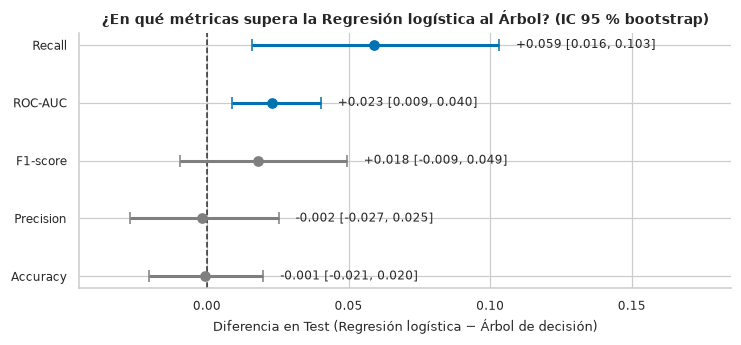

Figura guardada en: resultados/figuras/p06_diferencias_bootstrap_test.png


In [2]:
comparacion = pd.read_csv(RESULTS_DIR / "comparacion_modelos_validacion_test.csv")
intervalos = pd.read_csv(RESULTS_DIR / "intervalos_bootstrap_test.csv")
diferencias = pd.read_csv(RESULTS_DIR / "diferencias_bootstrap_test.csv")

print("=== Desempeño en Validation y Test ===")
display(comparacion)

print("\n=== Diferencias pareadas en Test (Bootstrap 95 %, 2000 remuestreos) ===")
diff_rl_ad = diferencias[diferencias["Comparación"] == f"{NOMBRE_LOGISTICA} − {NOMBRE_ARBOL}"].copy()
display(diff_rl_ad)

fig, ax = plt.subplots(figsize=(6.8, 3.2))
metricas_orden = ["Accuracy", "Precision", "F1-score", "ROC-AUC", "Recall"]
sub = diff_rl_ad.set_index("Métrica").loc[metricas_orden].reset_index()

y_pos = np.arange(len(sub))
colores = ["#0072B2" if sig else "#7f7f7f" for sig in sub["El IC excluye 0"]]

ax.axvline(0, color="black", linestyle="--", linewidth=1.0, alpha=0.8)
for i, fila in sub.iterrows():
    ax.errorbar(
        x=fila["Diferencia"],
        y=i,
        xerr=[[fila["Diferencia"] - fila["IC inferior"]], [fila["IC superior"] - fila["Diferencia"]]],
        fmt="o",
        color=colores[i],
        ecolor=colores[i],
        elinewidth=2.0,
        capsize=4,
        markersize=6,
    )
    etiqueta = f"{fila['Diferencia']:+.3f} [{fila['IC inferior']:.3f}, {fila['IC superior']:.3f}]"
    ax.text(fila["IC superior"] + 0.006, i, etiqueta, va="center", fontsize=8)

ax.set_yticks(y_pos)
ax.set_yticklabels(sub["Métrica"])
ax.set_xlim(-0.045, 0.185)
ax.set_xlabel("Diferencia en Test (Regresión logística − Árbol de decisión)")
ax.set_title("¿En qué métricas supera la Regresión logística al Árbol? (IC 95 % bootstrap)")
plt.tight_layout()
ruta_fig1 = graficos.guardar_figura(fig, "p06_diferencias_bootstrap_test.png")
plt.show()
print("Figura guardada en:", ruta_fig1.relative_to(ROOT))


## 3. Interpretación de los resultados

### 3.1 Tres razones por las que la Regresión Logística iguala o supera al Árbol
1. **Señal mayormente aditiva y monótona:** Como anticipó el EDA, el abandono cae sostenidamente con `tenure` y aumenta con `Contract = Month-to-month` y `InternetService = Fiber optic`. Un modelo lineal en los *log-odds* captura esta estructura con 46 coeficientes globales ajustados sobre todos los 4225 clientes de Train.
2. **Fragmentación de datos en el árbol:** Al dividir sucesivamente el espacio, cada hoja estima probabilidades con pocos registros (mínimo 20). En Test, el árbol produce apenas **alrededor de 100 probabilidades distintas** (95 al redondear a 6 decimales), frente a **1407** de la regresión logística; esto produce un ordenamiento más grueso (menor ROC-AUC) y una mayor brecha Train–Validation (`0.066` frente a `0.012`). Además, un árbol de solo **8 hojas** (`max_depth=3`) ya logra F1 = `0.608` en Validation, prácticamente indistinguible del árbol elegido de 132 hojas (`0.619`).
3. **Aporte acotado de las interacciones:** La ventaja no lineal del árbol solo destaca en un nicho pequeño: entre clientes sin internet (`InternetService = No`), el árbol detecta 11 de los 25 abandonos y la regresión logística ninguno, pero son pocos casos para revertir el balance global.

### 3.2 El peso del desbalance y su efecto en calibración
* Mover la fuerza de regularización `C` en la regresión logística con L2 y ponderación apenas varió el F1 en Validation (entre `0.610` y `0.625`).
* Activar `class_weight="balanced"` (pesos `1.884` para `Churn=1` y `0.681` para `Churn=0`, razón de costo `2.77:1`) fue la decisión de mayor impacto: elevó el F1 máximo de Validation de `0.593` a `0.625` en regresión logística y de `0.579` a `0.619` en árbol, a costa de señalar al `40.6 %` de Test (572 alertas, ~50 % falsas alarmas) y **descalibrar las probabilidades** (media estimada de `0.414` y `0.389` frente a tasa real `0.265`).


In [3]:
cfg_rl = leer_json(RESULTS_DIR / "configuracion_regresion_logistica.json")
cfg_ad = leer_json(RESULTS_DIR / "configuracion_arbol_decision.json")
grilla_rl = pd.read_csv(RESULTS_DIR / "resultados_regresion_logistica_grilla_validacion.csv")
grilla_ad = pd.read_csv(RESULTS_DIR / "resultados_arbol_decision_grilla_validacion.csv")
pred_test = pd.read_csv(RESULTS_DIR / "predicciones_test.csv")
odds_rl = pd.read_csv(RESULTS_DIR / "razones_de_odds_regresion_logistica.csv")
perm_rl = pd.read_csv(RESULTS_DIR / "importancia_permutacion_regresion_logistica_validacion.csv")
perm_ad = pd.read_csv(RESULTS_DIR / "importancia_permutacion_arbol_decision_validacion.csv")

# 1. Brecha Train - Validation y efecto de class_weight
brecha_rl = cfg_rl["metricas_train"]["F1-score"] - cfg_rl["metricas_validation"]["F1-score"]
brecha_ad = cfg_ad["metricas_train"]["F1-score"] - cfg_ad["metricas_validation"]["F1-score"]

rl_sin_pesos = grilla_rl[grilla_rl["class_weight"].isna()].sort_values("F1-score (Validation)", ascending=False).iloc[0]
ad_sin_pesos = grilla_ad[grilla_ad["class_weight"].isna()].sort_values("F1-score (Validation)", ascending=False).iloc[0]
ad_8_hojas = grilla_ad[(grilla_ad["class_weight"] == "balanced") & (grilla_ad["max_depth"] == 3) & (grilla_ad["min_samples_leaf"] == 20)].iloc[0]

print(f"Brecha F1 (Train - Validation): RL = {brecha_rl:.3f} | AD = {brecha_ad:.3f}")
print(f"Mejor F1 Validation sin ponderar: RL = {rl_sin_pesos['F1-score (Validation)']:.3f} | AD = {ad_sin_pesos['F1-score (Validation)']:.3f}")
print(f"Mejor F1 Validation con balanced: RL = {cfg_rl['metricas_validation']['F1-score']:.3f} | AD (132 hojas) = {cfg_ad['metricas_validation']['F1-score']:.3f} | AD (8 hojas, prof=3) = {ad_8_hojas['F1-score (Validation)']:.3f}")

# 2. Probabilidades distintas y calibración en Test
p_rl = pred_test[f"Probabilidad · {NOMBRE_LOGISTICA}"]
p_ad = pred_test[f"Probabilidad · {NOMBRE_ARBOL}"]
print(f"\nProbabilidades distintas en Test: RL = {p_rl.nunique()} | AD = {p_ad.nunique()} ({p_ad.round(6).nunique()} redondeadas)")
print(f"Media de probabilidad estimada en Test: RL = {p_rl.mean():.3f} | AD = {p_ad.mean():.3f} | Tasa real = {pred_test['Churn real'].mean():.3f}")
print(f"Clientes señalados en Test (RL): {int((pred_test[f'Predicción · {NOMBRE_LOGISTICA}'] == 1).sum())} de {len(pred_test)} ({100 * (pred_test[f'Predicción · {NOMBRE_LOGISTICA}'] == 1).mean():.1f} %)")

print("\n=== Top 5 variables por importancia por permutación (Validation) ===")
top_perm = pd.DataFrame({
    "Variable (RL)": perm_rl["Variable"].head(5).values,
    "Caída F1 (RL)": perm_rl["Caída de F1-score (media)"].head(5).values,
    "Variable (AD)": perm_ad["Variable"].head(5).values,
    "Caída F1 (AD)": perm_ad["Caída de F1-score (media)"].head(5).values,
})
display(top_perm)

print("\n=== Principales razones de odds (Regresión logística) ===")
display(odds_rl.head(10))


Brecha F1 (Train - Validation): RL = 0.012 | AD = 0.066
Mejor F1 Validation sin ponderar: RL = 0.593 | AD = 0.579
Mejor F1 Validation con balanced: RL = 0.625 | AD (132 hojas) = 0.619 | AD (8 hojas, prof=3) = 0.608

Probabilidades distintas en Test: RL = 1407 | AD = 99 (95 redondeadas)
Media de probabilidad estimada en Test: RL = 0.414 | AD = 0.389 | Tasa real = 0.265
Clientes señalados en Test (RL): 572 de 1409 (40.6 %)

=== Top 5 variables por importancia por permutación (Validation) ===


,Variable (RL),Caída F1 (RL),Variable (AD),Caída F1 (AD)
0,tenure,0.1261,Contract,0.1804
1,Contract,0.0375,InternetService,0.1379
2,InternetService,0.0144,tenure,0.1160
3,PaymentMethod,0.0096,TotalCharges,0.0567
4,TotalCharges,0.0082,OnlineSecurity,0.0191



=== Principales razones de odds (Regresión logística) ===


,Variable,Categoría,Referencia,Diferencia de log-odds,Razón de odds
0,InternetService,No,Fiber optic,-1.6466,0.1927
1,Contract,Two year,Month-to-month,-1.4344,0.2383
2,Contract,One year,Month-to-month,-0.7683,0.4638
3,InternetService,DSL,Fiber optic,-0.7014,0.4959
4,PhoneService,No,Yes,0.6410,1.8984
5,OnlineSecurity,Yes,No,-0.4132,0.6616
6,PaymentMethod,Bank transfer (automatic),Electronic check,-0.3928,0.6752
7,PaymentMethod,Credit card (automatic),Electronic check,-0.3712,0.6899
8,TechSupport,Yes,No,-0.3698,0.6909
9,PaperlessBilling,No,Yes,-0.2803,0.7556


## 4. Análisis del techo de información: los 61 abandonos no detectados

La diferencia entre algoritmos es modesta porque el límite principal reside en la información disponible. En Test, ambos modelos coinciden en el **84.7 %** de las predicciones y hay **61 clientes que abandonaron (16.3 % de los 374 abandonos)** que **ninguno de los dos modelos logra detectar**.

Al examinar su perfil, estos 61 clientes resultan prácticamente indistinguibles de quienes permanecen en el servicio (alta antigüedad mediana, menor proporción de contrato mensual y fibra óptica, y cargos moderados). Para identificarlos harían falta señales externas al dataset: reclamos, calidad técnica del servicio, cambios recientes de plan o promociones de la competencia.


=== Coincidencia de aciertos y errores en Test ===


,Clase real,Situación,Clientes,Proporción
0,Clientes que abandonaron (Churn=1),Ambos modelos: detecta,249,0.6658
1,Clientes que abandonaron (Churn=1),Solo Regresión logística: detecta,43,0.1150
2,Clientes que abandonaron (Churn=1),Solo Árbol de decisión: detecta,21,0.0561
3,Clientes que abandonaron (Churn=1),Ninguno: detecta,61,0.1631
4,Clientes que se quedaron (Churn=0),Ambos modelos: da falsa alarma,193,0.1865
5,Clientes que se quedaron (Churn=0),Solo Regresión logística: da falsa alarma,87,0.0841
6,Clientes que se quedaron (Churn=0),Solo Árbol de decisión: da falsa alarma,64,0.0618
7,Clientes que se quedaron (Churn=0),Ninguno: da falsa alarma,691,0.6676


Acuerdo total entre RL y AD en Test: 84.7 %

=== Perfil comparado: ¿por qué fallan ambos modelos en 61 abandonos? ===


,Grupo (Test),Clientes (n),Antigüedad mediana (meses),Contrato mensual (%),Fibra óptica (%),Cargo mensual mediano (USD)
0,Abandonan y ambos detectan,249,4.0000,99.5984,80.7229,79.0000
1,Abandonan y ninguno detecta (FN),61,35.0000,44.2623,34.4262,64.4000
2,Permanecen (Churn=0),1035,38.0000,42.8986,34.8792,64.6500


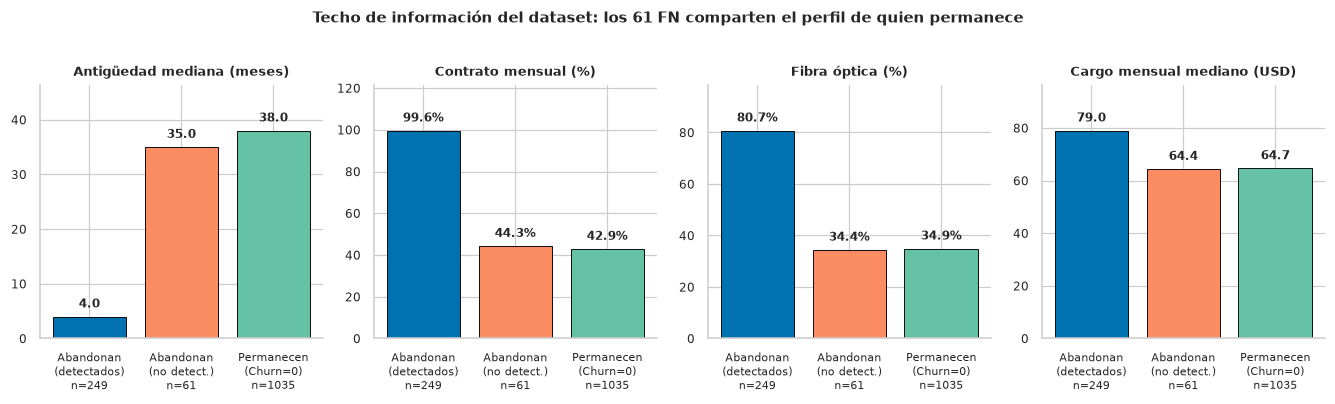

Figura guardada en: resultados/figuras/p06_techo_informacion_61_fn.png


In [4]:
coincidencia = pd.read_csv(RESULTS_DIR / "coincidencia_errores_test.csv")
print("=== Coincidencia de aciertos y errores en Test ===")
display(coincidencia)

datos = pd.read_csv(DATA_CSV)
test_orig = datos.loc[pred_test["Fila en el CSV original"]].reset_index(drop=True)
rl = pred_test[f"Predicción · {NOMBRE_LOGISTICA}"]
ad = pred_test[f"Predicción · {NOMBRE_ARBOL}"]
abandona = pred_test["Churn real"] == 1

acuerdo = (rl == ad).mean()
print(f"Acuerdo total entre RL y AD en Test: {100 * acuerdo:.1f} %")

grupos = {
    "Abandonan y ambos detectan": abandona & (rl == 1) & (ad == 1),
    "Abandonan y ninguno detecta (FN)": abandona & (rl == 0) & (ad == 0),
    "Permanecen (Churn=0)": ~abandona,
}

filas_perfil = []
for nombre, filtro in grupos.items():
    g = test_orig[filtro]
    filas_perfil.append({
        "Grupo (Test)": nombre,
        "Clientes (n)": len(g),
        "Antigüedad mediana (meses)": g["tenure"].median(),
        "Contrato mensual (%)": 100 * (g["Contract"] == "Month-to-month").mean(),
        "Fibra óptica (%)": 100 * (g["InternetService"] == "Fiber optic").mean(),
        "Cargo mensual mediano (USD)": g["MonthlyCharges"].median(),
    })

perfil_df = pd.DataFrame(filas_perfil)
print("\n=== Perfil comparado: ¿por qué fallan ambos modelos en 61 abandonos? ===")
display(perfil_df)

fig, axes = plt.subplots(1, 4, figsize=(12.2, 3.5))
etiquetas_cortas = ["Abandonan\n(detectados)\nn=249", "Abandonan\n(no detect.)\nn=61", "Permanecen\n(Churn=0)\nn=1035"]
colores_grupos = ["#0072B2", "#fc8d62", "#66c2a5"]

metricas_perfil = [
    ("Antigüedad mediana (meses)", "Antigüedad mediana (meses)"),
    ("Contrato mensual (%)", "Contrato mensual (%)"),
    ("Fibra óptica (%)", "Fibra óptica (%)"),
    ("Cargo mensual mediano (USD)", "Cargo mensual mediano (USD)"),
]

for ax, (col, titulo) in zip(axes, metricas_perfil):
    vals = perfil_df[col].values
    bars = ax.bar(range(3), vals, color=colores_grupos, edgecolor="black", linewidth=0.6)
    ax.set_xticks(range(3))
    ax.set_xticklabels(etiquetas_cortas, fontsize=7.5)
    ax.set_title(titulo, fontsize=8.5)
    ax.set_ylim(0, max(vals) * 1.22)
    for bar, v in zip(bars, vals):
        fmt = f"{v:.1f}%" if "%" in col else f"{v:.1f}"
        ax.text(bar.get_x() + bar.get_width() / 2, v + max(vals) * 0.03, fmt, ha="center", va="bottom", fontsize=8, fontweight="bold")

fig.suptitle("Techo de información del dataset: los 61 FN comparten el perfil de quien permanece", fontsize=10, fontweight="bold", y=1.03)
plt.tight_layout()
ruta_fig2 = graficos.guardar_figura(fig, "p06_techo_informacion_61_fn.png")
plt.show()
print("Figura guardada en:", ruta_fig2.relative_to(ROOT))


## 5. Sesgos, equidad y generalización (`gender` y `SeniorCitizen`)

* **`gender`:** Prácticamente neutro. En la regresión logística el OR es `1.05` (`Female` vs `Male`) y las tasas de error son casi idénticas (Recall `0.782` vs `0.779`; tasa de falsos positivos `0.271` vs `0.270`).
* **`SeniorCitizen`:** Los adultos mayores que permanecen reciben una falsa alarma casi el **doble de veces** que el resto (`0.476` vs `0.243` en RL; `0.411` vs `0.226` en Árbol), aunque su Recall también es mayor (`0.929` vs `0.728`) y la Precision de las alertas es más alta (`0.607` vs `0.476`) por tener una tasa base de abandono mayor (`44.1 %` vs `23.3 %` en Test).
* **Origen estructural del sesgo:** El efecto directo de `SeniorCitizen` es pequeño (OR = `1.18`), pero en el dataset completo los adultos mayores concentran mucho más contrato mensual (`70.7 %` vs `52.0 %`) y fibra óptica (`72.8 %` vs `38.4 %`). Por ello, **eliminar `SeniorCitizen` no suprimiría la disparidad**, pues contrato e internet actuarían como variables sustitutas (*proxies*).
* **Lectura ética:** La equidad depende del uso de la alerta. Si activa un beneficio de retención (descuento/soporte), el grupo menos atendido sería el de contratos largos; si activa penalidades o trato restrictivo, perjudicaría a adultos mayores y clientes de contrato mensual.


=== Métricas por subgrupo sensible en Test ===


,Variable,Grupo,Clientes,Abandonos,Tasa de abandono,Modelo,Recall,Tasa de falsos positivos,Precision
20,SeniorCitizen,0,1187,276,0.2325,Regresión logística,0.7283,0.2426,0.4763
21,SeniorCitizen,0,1187,276,0.2325,Árbol de decisión,0.6884,0.2261,0.4798
22,SeniorCitizen,1,222,98,0.4414,Regresión logística,0.9286,0.4758,0.6067
23,SeniorCitizen,1,222,98,0.4414,Árbol de decisión,0.8163,0.4113,0.6107
32,gender,Female,687,193,0.2809,Regresión logística,0.7824,0.2713,0.5298
33,gender,Female,687,193,0.2809,Árbol de decisión,0.7150,0.2551,0.5227
34,gender,Male,722,181,0.2507,Regresión logística,0.7790,0.2699,0.4913
35,gender,Male,722,181,0.2507,Árbol de decisión,0.7293,0.2421,0.5019



=== Composición estructural por SeniorCitizen (dataset completo, n=7043) ===


,Contrato mensual (%),Fibra óptica (%)
SeniorCitizen,,
0,52.0000,38.4000
1,70.7000,72.8000


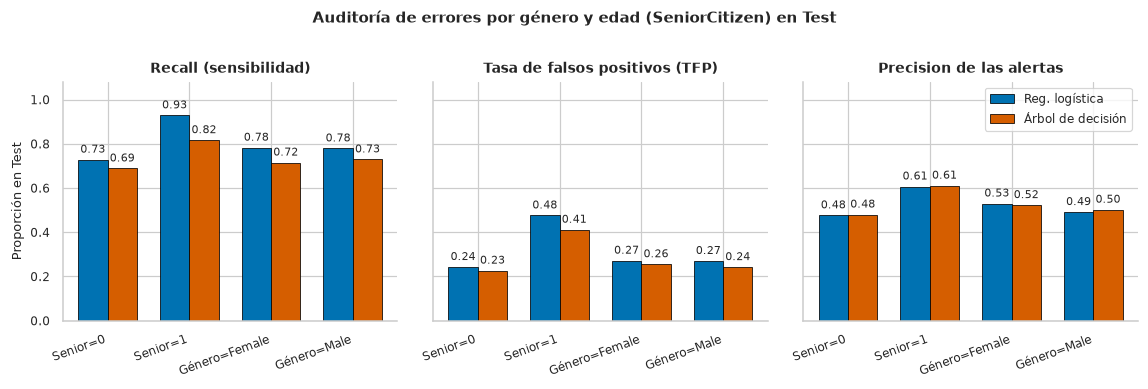

Figura guardada en: resultados/figuras/p06_equidad_sesgo_subgrupos.png


In [5]:
subgrupos = pd.read_csv(RESULTS_DIR / "errores_por_subgrupo_test.csv")
equidad = subgrupos[subgrupos["Variable"].isin(["gender", "SeniorCitizen"])].copy()

print("=== Métricas por subgrupo sensible en Test ===")
display(equidad[["Variable", "Grupo", "Clientes", "Abandonos", "Tasa de abandono", "Modelo", "Recall", "Tasa de falsos positivos", "Precision"]])

resumen_sc = (
    datos.assign(
        contrato_mensual=datos["Contract"].eq("Month-to-month"),
        fibra_optica=datos["InternetService"].eq("Fiber optic"),
    )
    .groupby("SeniorCitizen")[["contrato_mensual", "fibra_optica"]]
    .mean()
    .mul(100)
    .round(1)
)
resumen_sc.columns = ["Contrato mensual (%)", "Fibra óptica (%)"]
print("\n=== Composición estructural por SeniorCitizen (dataset completo, n=7043) ===")
display(resumen_sc)

# Gráfico comparativo de equidad para Regresión logística y Árbol
eq_rl = equidad[equidad["Modelo"] == NOMBRE_LOGISTICA].copy()
eq_rl["Etiqueta"] = eq_rl["Variable"].replace({"SeniorCitizen": "Senior", "gender": "Género"}) + "=" + eq_rl["Grupo"].astype(str)

eq_ad = equidad[equidad["Modelo"] == NOMBRE_ARBOL].copy()
eq_ad["Etiqueta"] = eq_ad["Variable"].replace({"SeniorCitizen": "Senior", "gender": "Género"}) + "=" + eq_ad["Grupo"].astype(str)

fig, axes = plt.subplots(1, 3, figsize=(10.5, 3.4), sharey=True)
metricas_eq = [
    ("Recall", "Recall (sensibilidad)"),
    ("Tasa de falsos positivos", "Tasa de falsos positivos (TFP)"),
    ("Precision", "Precision de las alertas"),
]

x = np.arange(len(eq_rl))
w = 0.36
for ax, (col, titulo) in zip(axes, metricas_eq):
    b1 = ax.bar(x - w/2, eq_rl[col].values, width=w, label="Reg. logística", color="#0072B2", edgecolor="black", linewidth=0.5)
    b2 = ax.bar(x + w/2, eq_ad[col].values, width=w, label="Árbol de decisión", color="#D55E00", edgecolor="black", linewidth=0.5)
    ax.set_xticks(x)
    ax.set_xticklabels(eq_rl["Etiqueta"].values, rotation=20, ha="right", fontsize=8)
    ax.set_title(titulo, fontsize=9)
    ax.set_ylim(0, 1.08)
    for b in list(b1) + list(b2):
        h = b.get_height()
        ax.text(b.get_x() + b.get_width()/2, h + 0.02, f"{h:.2f}", ha="center", va="bottom", fontsize=7)

axes[0].set_ylabel("Proporción en Test")
axes[2].legend(loc="upper right", frameon=True)
fig.suptitle("Auditoría de errores por género y edad (SeniorCitizen) en Test", fontsize=10, fontweight="bold", y=1.02)
plt.tight_layout()
ruta_fig3 = graficos.guardar_figura(fig, "p06_equidad_sesgo_subgrupos.png")
plt.show()
print("Figura guardada en:", ruta_fig3.relative_to(ROOT))


## 6. Limitaciones del estudio

### Del conjunto de datos
* **Muestra ficticia y alcance geográfico:** Conjunto de ejemplo de IBM sin información sobre el muestreo; no es generalizable a operadores reales ni al mercado peruano.
* **Corte transversal sin marcas temporales:** No existen fechas de registro de las variables respecto del evento de abandono, lo que impide realizar validación temporal (*train* en pasado, *test* en futuro) y descartar completamente una fuga temporal de origen.
* **Sesgo de supervivencia en `tenure`:** Quienes tienen mayor antigüedad son los que no abandonaron antes; el efecto medido describe a quienes sobrevivieron hasta ese mes, no un efecto causal sobre clientes nuevos.
* **Imputación por supuesto:** Los 11 faltantes de `TotalCharges` (`tenure = 0`) se imputaron con `0`; es coherente conceptualmente, pero no verificable.

### De la metodología
* **Validación *hold-out* única (semilla 42):** Con 1409 registros en Validation, diferencias de `0.002` a `0.01` en F1 entran en el ruido muestral y podrían variar con otra partición.
* **Ligero optimismo de Validation:** Al elegir el máximo de 36 y 42 configuraciones, el F1 cae levemente en Test (`0.625 → 0.617` en RL; `0.619 → 0.599` en AD).
* **Umbral fijo en 0.5 sin matriz de costos:** No se dispone de los costos reales de retener vs perder a un cliente para optimizar el punto de corte.
* **Familias de modelos y colinealidad:** Solo se compararon dos familias sin ensambles ni ingeniería de interacciones; además, la codificación *one-hot* completa impide interpretar coeficientes individuales sueltos (por eso se reportan razones de *odds* por contraste) y la correlación entre `tenure` y `TotalCharges` (`0.834` en Train) puede subestimar la importancia por permutación individual.

### De los resultados
* **Incertidumbre apreciable y subgrupos pequeños:** Los intervalos bootstrap rondan `±0.04` en F1; subgrupos como `Contract = Two year` (9 abandonos) o `InternetService = No` (25 abandonos) tienen tasas imprecisas.
* **Asociación, no causalidad:** Las razones de *odds* y reglas describen patrones observacionales; cambiar el contrato de un cliente no garantiza causalmente el mismo cambio de riesgo.
* **Probabilidades no calibradas:** Producto de `class_weight="balanced"`.


## 7. Respuestas a las preguntas de investigación, aprendizajes y trabajo futuro

### Respuestas a las 6 preguntas de investigación
1. **¿Qué características presentan diferencias en la proporción de abandono observado?**
   `Contract`, `tenure`, `InternetService`, `PaymentMethod` y servicios adicionales (`OnlineSecurity`, `TechSupport`). Ambos modelos coinciden en que `Contract`, `tenure` e `InternetService` son las tres variables más importantes por permutación.
2. **¿Las diferencias por contrato se mantienen al comparar grupos de antigüedad similares?**
   Sí. Con las demás variables fijas (incluida la antigüedad), un contrato de dos años multiplica los *odds* de abandono por `0.24` frente al mensual, y uno de un año por `0.46`. En el árbol, `Contract` es la primera división (`43.1 %` de abandono en mensual vs `6.3 %` en el resto de Train).
3. **¿Cómo se relacionan el tipo de internet y los servicios adicionales con el abandono, y qué diferencias permanecen dentro de cada contrato?**
   La fibra óptica se asocia con mayor abandono incluso dentro del contrato mensual (`55.5 %` vs `28.1 %` en el árbol; OR de DSL frente a fibra = `0.50`). Contar con `OnlineSecurity` o `TechSupport` se asocia con menor abandono (OR = `0.66` y `0.69`).
4. **¿Qué problemas de calidad, representatividad y fuga de información deben considerarse antes del modelado?**
   Se imputaron con cero los 11 faltantes de `TotalCharges`, se excluyó `customerID`, los preprocesadores se ajustaron solo con Train y Test se consultó una sola vez. La representatividad (muestra ficticia sin fechas) sigue siendo la limitación estructural principal.
5. **¿En qué medida la regresión logística y el árbol de decisión permiten identificar clientes que abandonan, en comparación con el clasificador de referencia?**
   El `DummyClassifier` detecta `0` de `374` abandonos en Test. La Regresión Logística detecta `292` (Recall `0.781`, F1 `0.617`, ROC-AUC `0.841`) y el Árbol `270` (Recall `0.722`, F1 `0.599`, ROC-AUC `0.818`), con Precision cercana a `0.51` y exactitud casi idéntica (`0.743`/`0.744` vs `0.735`).
6. **¿Qué diferencias presentan ambos modelos en su desempeño e interpretabilidad, y qué características resultan relevantes?**
   La regresión logística supera al árbol en Recall y ROC-AUC; en F1 la diferencia no es concluyente. Se interpreta globalmente mediante razones de *odds*. El árbol se expresa en reglas, pero el elegido tiene 132 hojas (solo legibles en sus primeros niveles), aunque un árbol de 8 hojas rinde casi igual (`0.608`). Ambos coinciden en `Contract`, `tenure` e `InternetService`.

### Principales aprendizajes
* **El tratamiento del desbalance pesó más que la regularización `C`.**
* **Cuantificar la incertidumbre con bootstrap evitó sobreafirmar ventajas en F1 dentro del ruido muestral.**
* **Mayor complejidad no implicó mejor generalización:** el árbol sin restricciones memorizó Train (`0.996` → `0.496` en Validation); restringir hojas hizo útil al árbol.
* **Fijar un protocolo común antes de modelar (P02)** garantizó comparabilidad justa entre los modelos del equipo.

### Trabajo futuro
1. **Validación cruzada estratificada** para estabilizar la selección de hiperparámetros.
2. **Optimización del umbral** usando una matriz de costos reales de negocio ($C_{\text{FP}}$ vs $C_{\text{FN}}$).
3. **Calibración de probabilidades** (Platt o regresión isotónica) si se requiere usar el *score* como probabilidad real.
4. **Nuevas variables, interacciones y modelos de ensamble** (*Random Forest*, *Gradient Boosting*) para reducir la varianza de un solo árbol.
5. **Validación temporal con datos reales de producción** y monitoreo continuo de sesgos por subgrupo.


## 8. Verificación de trazabilidad de artefactos

Se comprueba que todos los archivos de resultados citados en la discusión existen en `resultados/`.


In [6]:
archivos_clave = [
    "configuracion_regresion_logistica.json",
    "configuracion_arbol_decision.json",
    "resultados_regresion_logistica_grilla_validacion.csv",
    "resultados_arbol_decision_grilla_validacion.csv",
    "comparacion_modelos_validacion_test.csv",
    "intervalos_bootstrap_test.csv",
    "diferencias_bootstrap_test.csv",
    "razones_de_odds_regresion_logistica.csv",
    "importancia_permutacion_regresion_logistica_validacion.csv",
    "importancia_permutacion_arbol_decision_validacion.csv",
    "coincidencia_errores_test.csv",
    "perfil_errores_test.csv",
    "errores_por_subgrupo_test.csv",
    "predicciones_test.csv",
    "figuras/p06_diferencias_bootstrap_test.png",
    "figuras/p06_techo_informacion_61_fn.png",
    "figuras/p06_equidad_sesgo_subgrupos.png",
]

estado = []
for rel in archivos_clave:
    ruta = RESULTS_DIR / rel
    estado.append({"Archivo en resultados/": rel, "Existe": ruta.is_file(), "Bytes": ruta.stat().st_size if ruta.is_file() else 0})

df_estado = pd.DataFrame(estado)
assert df_estado["Existe"].all(), "Faltan archivos en resultados/"
display(df_estado)
print("Todos los artefactos de trazabilidad verificados correctamente.")


,Archivo en resultados/,Existe,Bytes
0,configuracion_regresion_logistica.json,True,874
1,configuracion_arbol_decision.json,True,891
2,resultados_regresion_logistica_grilla_validaci...,True,7812
3,resultados_arbol_decision_grilla_validacion.csv,True,8931
4,comparacion_modelos_validacion_test.csv,True,677
5,intervalos_bootstrap_test.csv,True,1153
6,diferencias_bootstrap_test.csv,True,1834
7,razones_de_odds_regresion_logistica.csv,True,1404
8,importancia_permutacion_regresion_logistica_va...,True,1991
9,importancia_permutacion_arbol_decision_validac...,True,1896


Todos los artefactos de trazabilidad verificados correctamente.
